In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import pickle

In [3]:
df = pd.read_csv("diamonds new.csv")

In [4]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [5]:
df.shape

(53940, 10)

In [6]:
df.columns

Index(['carat', 'cut', 'color', 'clarity', 'depth', 'table', 'price', 'x', 'y',
       'z'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


In [8]:
df.describe()

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [9]:
df.isnull().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [10]:
df.duplicated().sum()

146

#### Define input features (x) and target (y)

In [11]:
x = df.drop(columns="price")
y = df["price"]

In [12]:
x.shape

(53940, 9)

In [13]:
y.shape

(53940,)

#### Split the data

In [14]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size = 0.25,
    random_state = 42
)

In [15]:
x_train.shape

(40455, 9)

In [16]:
x_test.shape

(13485, 9)

#### Identify numerical and categorical columns

In [17]:
numerical_cols = x_train.select_dtypes(
    include = ["int64","float64"]
).columns.tolist()

In [18]:
categorical_cols = x_train.select_dtypes(
    include = ["object","category","bool"]
).columns.tolist()

#### Create Preprocessing Pipeline

In [19]:
numeric_pipeline = Pipeline(
    steps = [
        ("imputer",SimpleImputer(strategy="mean")),
        ("scaler",StandardScaler())
    ]
)

In [20]:
categorical_pipeline = Pipeline(
    steps = [
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(handle_unknown="ignore"))
    ]
)

#### Combine Preprocessing using Column Transformer

In [21]:
preprocessor = ColumnTransformer(
    [
        ("numeric",numeric_pipeline,numerical_cols),
        ("categorical",categorical_pipeline,categorical_cols)
    ]
)

In [22]:
x_train_processed = preprocessor.fit_transform(x_train)

print("Original shape:", x_train.shape)
print("Processed shape:", x_train_processed.shape)

Original shape: (40455, 9)
Processed shape: (40455, 26)


In [23]:
X_test_processed = preprocessor.transform(x_test)

print("Test original shape:", x_test.shape)
print("Test processed shape:", X_test_processed.shape)

Test original shape: (13485, 9)
Test processed shape: (13485, 26)


#### Create the KNN Regression Model

In [24]:
knn = KNeighborsRegressor(
    n_neighbors=5,
    weights="uniform",
    metric="minkowski",
    p=2)

#### Build the ML pipeline

In [25]:
model = Pipeline(
    steps = [
        ("preprocessor",preprocessor),
        ("knn",knn)
    ]
)

#### Train the Model

In [26]:
model.fit(x_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['carat', 'depth', 'table',
                                                   'x', 'y', 'z']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['cut', 'color',
                                                   'clarity'])])),
                ('knn', KNeighborsRegressor())])

#### Make Prediction

In [27]:
y_pred = model.predict(x_test)
print(y_test.head(10).values)
print(y_pred[:10])

D:\New folder\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "D:\New folder\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "D:\New folder\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "D:\New folder\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "D:\New folder\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^

[ 559 2201 1238 1304 6901 3011 1765 1679 2102 4789]
[ 586.4 2427.6 1083.4 1196.2 9642.2 3434.4 1776.8 1829.4 2390.6 6291. ]


#### Evaluate the Model

In [28]:
mae = mean_absolute_error(y_test,y_pred)
rmse = np.sqrt(mean_squared_error(y_test,y_pred))
r2 = r2_score(y_test,y_pred)
print("MAE:",round(mae,2))
print("RMSE:",round(rmse,2))
print("R2:",round(r2,2))

MAE: 408.16
RMSE: 785.87
R2: 0.96


#### Compare Actual and Predicted Prices

In [29]:
results = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})
results['Error'] = (results['Actual Price'] - results['Predicted Price']).abs()
results.head(10)

,Actual Price,Predicted Price,Error
0,559,586.4,27.4
1,2201,2427.6,226.6
2,1238,1083.4,154.6
3,1304,1196.2,107.8
4,6901,9642.2,2741.2
5,3011,3434.4,423.4
6,1765,1776.8,11.8
7,1679,1829.4,150.4
8,2102,2390.6,288.6
9,4789,6291.0,1502.0


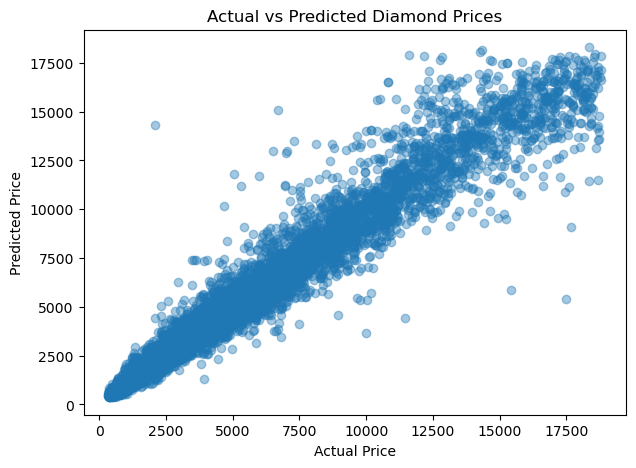

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred, alpha=0.4)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Diamond Prices")

plt.show()

#### Save the trained pipeline using pickle

In [31]:
with open("diamond_price_prediction_model.pkl", "wb") as file:
    pickle.dump(model, file)

In [32]:
print("Model saved successfully")

Model saved successfully


In [33]:
with open("diamond_price_prediction_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)
sample_prediction = loaded_model.predict(x_test.iloc[:1])
print("Sample Prediction:", sample_prediction[0])

Sample Prediction: 586.4


In [34]:
import sklearn
import sys

print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)

Python version: 3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]
Scikit-learn version: 1.4.2


In [35]:
import os
print(os.path.abspath("diamond_price_prediction_model.pkl"))

C:\Users\BIDYASHREE\diamond_price_prediction_model.pkl
